# Лабораторная работа № 2. Линейная регрессия
## Предсказание времени реакции школьников

Продолжаю работу с данными первой лабораторной: `HW_001_001.csv`. Предсказываю время реакции `react` по возрасту, уровню NO2 и другим известным характеристикам. Главная цель: проверить, что дают разные признаки и способы обработки, а также понять ограничения линейной модели.

### Требования лабораторной работы

| Требование | Раздел |
|---|---|
| Данные, задача, смысл ошибки и гипотезы, 2 балла | 1 |
| Разделение, предобработка, простой прогноз, один признак и LinearRegression, 3 балла | 2–4 |
| Наблюдения, гипотезы, эксперименты и сравнение по перекрёстной проверке, 5 баллов | 5–7 |
| Финальная оценка, графики ошибок, коэффициенты и 10 новых примеров, 3 балла | 8–10 |
| Выводы и обсуждение, 2 балла | 11 |


## 1. Данные, задача и гипотезы

**Напомню, что в этом датасете за данные.**
В исходном файле 1089 наблюдений и 22 столбца. 
Охват - 39 школ Барселоны в 2012–2013 годах. 
Одна строка содержит результат тестирования ребёнка и его характеристики.

**Что предсказываем:** время реакции в миллисекундах. Чем оно меньше, тем быстрее ответ. 

**Доступные признаки:** NO2 дома и в классе, возраст, возраст поступления в школу, пол, класс, семейные характеристики, образование родителей, шум, озеленение, осадки и социальные индексы. 

`react` - цель. `correct` и `omissions` исключаю: это результаты того же теста, которые до его проведения неизвестны. 

### Начальные гипотезы
1. Возраст даст заметную часть качества: в первой лабораторной старшие дети в среднем отвечали быстрее
2. Остальные числовые признаки и категории помогут, но прирост может быть небольшим
3. Регуляризация Ridge может сделать модель устойчивее при связанных признаках и редких категориях
4. Квадраты и сочетания возраста и NO2 могут описать зависимости, которые не видны простой прямой
5. Логарифмирование времени реакции может уменьшить влияние медленных ответов, но ухудшить прогноз именно для них

In [15]:
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, ShuffleSplit, cross_validate, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score, PredictionErrorDisplay
from joblib import dump, load

sns.set_theme()
ARTIFACTS = Path('lab2_artifacts')
ARTIFACTS.mkdir(exist_ok=True)
df = pd.read_csv(ARTIFACTS / 'HW_001_001.csv')
print('Исходная таблица:', df.shape)
print('Полные дубликаты:', df.duplicated().sum())
pd.DataFrame({'Тип': df.dtypes, 'Пропусков': df.isna().sum()})

Исходная таблица: (1089, 22)
Полные дубликаты: 0


,Тип,Пропусков
react,float64,5
correct,float64,5
omissions,float64,5
no2_class,float64,0
no2_home,float64,0
age,float64,0
age0,float64,7
sex,str,0
grade,str,0
overweight,str,26


## 2. Подготовка и разделение данных

Исключаю только пять строк без `react`: обучать и оценивать прогноз по ним нельзя. Не удаляю медленные ответы и большие значения загрязнения без подтверждения ошибки. Пропуски во входных признаках будут заполняться внутри Pipeline.

Сначала выделяю 20% строк для финальной проверки с фиксированным `random_state=2026`. Оставшиеся 80% использую для всех экспериментов. Внутри них задаю пять одинаковых случайных разбиений `ShuffleSplit`: на каждом 80% внутренних строк для обучения, 20% для проверки.

Все модели и параметры сравниваются по одним и тем же внутренним разбиениям. Заполнение пропусков и масштабирование каждый раз обучаются только на соответствующей внутренней обучающей части. Финальные 20% не участвуют в подборе признаков, преобразований или `alpha`.

In [16]:
data = df[df['react'].isna() == False].copy()
num_columns = ['age', 'no2_class', 'no2_home', 'age0', 'siblings_old',
               'siblings_young', 'sev_home', 'green_home', 'noise_school',
               'sev_school', 'precip']
cat_columns = ['sex', 'grade', 'overweight', 'lbweight', 'breastfeed',
               'msmoke', 'meducation', 'feducation']
feature_columns = num_columns + cat_columns
X = data[feature_columns].copy()
y = data['react'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2026)
cv_rule = ShuffleSplit(n_splits=5, test_size=0.2, random_state=42)
cv_splits = list(cv_rule.split(X_train, y_train))
print('После исключения пустых значений:', data.shape)
print('Для обучения и экспериментов:', X_train.shape)
print('Для финальной проверки:', X_test.shape)
assert len(feature_columns) == 19
assert len(X_train.index.intersection(X_test.index)) == 0
assert y_train.index.equals(X_train.index)

split_table = pd.DataFrame({'Исходная строка': X.index,
                           'Часть': ['обучение' if i in X_train.index else 'финальная проверка'
                                     for i in X.index]})
split_table.to_csv(ARTIFACTS / 'split.csv', index=False)
y_train.describe()

После исключения пустых значений: (1084, 22)
Для обучения и экспериментов: (867, 19)
Для финальной проверки: (217, 19)


count     867.000000
mean      743.061959
std       143.310302
min       434.071429
25%       632.628804
50%       721.048387
75%       839.083403
max      1303.259843
Name: react, dtype: float64

## 3. Обработка признаков и метрики

Числовые пропуски заполню медианами, затем масштабирую через `StandardScaler`. Категориальные пропуски заполняю самым частым значением обучающей части. 

Категории кодирую через `OneHotEncoder`. `drop='first'` убирает один столбец из каждой категории, чтобы избежать точной зависимости с константой обычной линейной регрессии. Неизвестные категории обрабатываются через `handle_unknown='ignore'`: их блок будет нулевым и совпадёт с базовой категорией. 

Для всех вариантов использую три метрики:

- **MAE:** средняя абсолютная ошибка, в миллисекундах. Чем меньше тем лучше.
- **RMSE:** корень из средней квадратичной ошибки, тоже в миллисекундах. Сильнее реагирует на большие ошибки. Чем меньше тем лучше.
- **R2:** сравнение с постоянным прогнозом среднего. Чем ближе к 1 темм лучше.

Главный критерий выбора заранее зафиксирую: минимальный средний RMSE на пяти внутренних разбиениях.

In [17]:
def make_preprocessor(numeric, categorical=None, degree=1):
    categorical = [] if categorical is None else categorical
    branches = []
    if numeric:
        if degree == 1:
            num_pipe = Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ])
            branches.append(('num', num_pipe, numeric))
        else:
            main = ['age', 'no2_class', 'no2_home']
            other = [name for name in numeric if name not in main]
            poly_pipe = Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
                ('scaler', StandardScaler())
            ])
            branches.append(('poly', poly_pipe, main))
            branches.append(('num', Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]), other))
    if categorical:
        cat_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
        ])
        branches.append(('cat', cat_pipe, categorical))
    return ColumnTransformer(branches, remainder='drop')


def make_model(numeric, categorical=None, model=None, degree=1, log_target=False):
    if model is None:
        model = LinearRegression()
    if log_target:
        model = TransformedTargetRegressor(
            regressor=model, func=np.log1p, inverse_func=np.expm1)
    return Pipeline([
        ('preprocessors', make_preprocessor(numeric, categorical, degree)),
        ('model', model)
    ])


def metrics(y_true, y_pred):
    return {
        'MAE, мс': np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))),
        'RMSE, мс': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    }


scoring = {'mae': 'neg_mean_absolute_error',
           'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'}
experiment_rows = []
fold_rows = []
model_templates = {}
evaluation_warnings = []


def remember(name, estimator, note):
    with warnings.catch_warnings(record=True) as caught:
        scores = cross_validate(estimator, X_train, y_train, cv=cv_splits,
                                scoring=scoring, return_train_score=True,
                                error_score='raise')
    evaluation_warnings.extend(str(item.message) for item in caught)
    row = {
        'Модель': name,
        'MAE проверки, мс': -scores['test_mae'].mean(),
        'RMSE проверки, мс': -scores['test_rmse'].mean(),
        'Разброс RMSE, мс': scores['test_rmse'].std(ddof=1),
        'R2 проверки': scores['test_r2'].mean(),
        'RMSE обучения, мс': -scores['train_rmse'].mean(),
        'Гипотеза': note
    }
    experiment_rows.append(row)
    model_templates[name] = estimator
    for fold in range(len(cv_splits)):
        fold_rows.append({'Модель': name, 'Разбиение': fold + 1,
                          'MAE, мс': -scores['test_mae'][fold],
                          'RMSE, мс': -scores['test_rmse'][fold],
                          'R2': scores['test_r2'][fold]})
    return row

## 4. Первые модели: постоянный прогноз, возраст и линейная регрессия

Самый простой вариант `DummyRegressor(strategy='mean')`, который всегда предсказывает среднее обучающей части. 

Затем обучаю линейную модель только по возрасту, модель по 11 числовым признакам и базовую `LinearRegression` по всем 19 признакам. 

In [18]:
DUMMY = 'Постоянный прогноз'
AGE = 'Только возраст'
NUM = 'Линейная: числовые'
BASE = 'Базовая линейная: все признаки'
RIDGE = 'Ridge: все признаки'
POLY = 'Ridge: квадраты и сочетания'
LOG = 'Ridge: логарифм времени реакции'

remember(DUMMY, DummyRegressor(strategy='mean'), 'Предсказать среднее без использования признаков')
remember(AGE, make_model(['age']), 'Возраст даст часть качества полной модели')
remember(NUM, make_model(num_columns), 'Другие числовые признаки дополнят возраст')
remember(BASE, make_model(num_columns, cat_columns), 'Категории помогут числовым признакам')
pd.DataFrame(experiment_rows)

,Модель,"MAE проверки, мс","RMSE проверки, мс","Разброс RMSE, мс",R2 проверки,"RMSE обучения, мс",Гипотеза
0,Постоянный прогноз,118.031522,148.548988,9.678105,-0.013574,141.830737,Предсказать среднее без использования признаков
1,Только возраст,109.406214,138.164223,5.987670,0.119995,131.534551,Возраст даст часть качества полной модели
2,Линейная: числовые,108.326715,136.706372,5.700966,0.138590,128.536764,Другие числовые признаки дополнят возраст
3,Базовая линейная: все признаки,105.639730,132.696285,3.815510,0.186666,122.414680,Категории помогут числовым признакам


**Результат.**   
Постоянный прогноз: RMSE 148,55 мс, MAE 118,03 мс, R2 -0.014.   
Только возраст: RMSE 138,16 мс, MAE 109,41 мс, R2 0.120.   
Все числовые признаки: RMSE 136,71 мс, MAE 108,33 мс, R2 0.139.   
Все признаки: RMSE 132,70 мс, MAE 105,64 мс, R2 0.187.  

Возраст уменьшил RMSE относительно постоянного прогноза на 10,38 мс. Это около 65,51% уменьшения RMSE, которое дала полная базовая модель относительно постоянного прогноза. Это доля уменьшения ошибки в этом сравнении, а не доля причинного влияния возраста. Средний RMSE уменьшился на 4,01 мс. 

## 5. Где ошибается базовая модель

Перед улучшениями рассмотрю первое внутреннее разбиение из пяти.   
Это часть обучающих данных, а не финальная проверка.   
Получаю прогноз базовой модели и смотрю остатки `истинное значение - прогноз`: положительный остаток означает, что время реакции недооценено, отрицательный означает завышение прогноза.

График остатков против истинного значения показывает, в какой части диапазона находятся крупные ошибки. Сам по себе наклон на таком графике ещё не доказывает неправильную форму модели: истинное значение входит в формулу остатка. Поэтому дополнительно смотрю остатки против прогноза и характеристики конкретных строк.

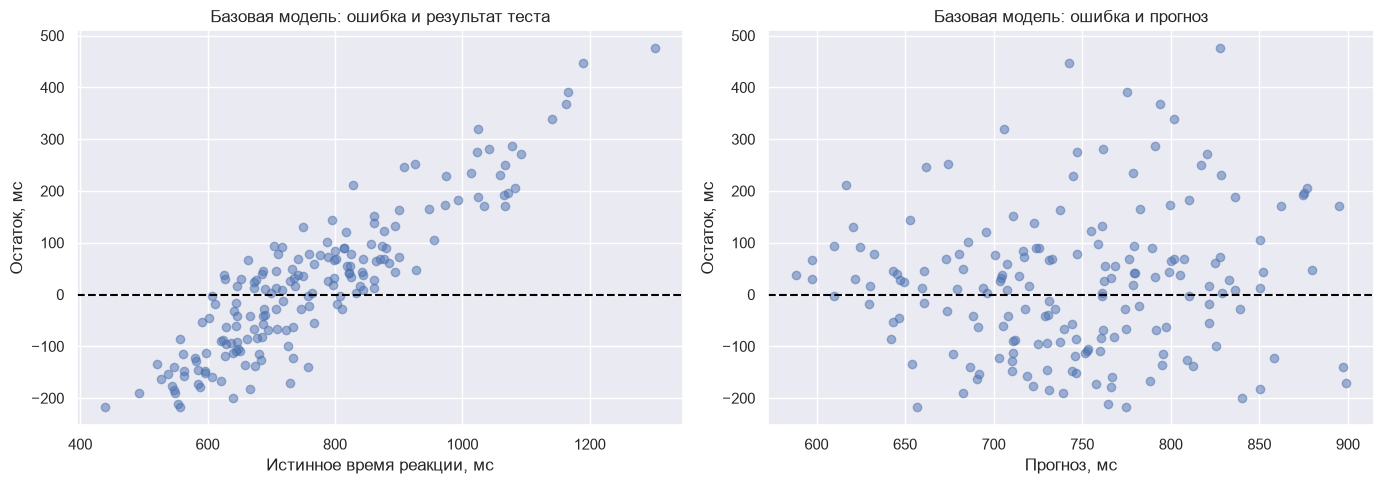

,age,no2_class,no2_home,age0,siblings_old,siblings_young,sev_home,green_home,noise_school,sev_school,...,overweight,lbweight,breastfeed,msmoke,meducation,feducation,Истинное время,Прогноз,Остаток,Абсолютная ошибка
811,7.797399,37.935078,64.873970,2.0,0.0,2.0,0.387097,0.148425,47.6,0.419355,...,Normal weight,Normal birthweight,<6 months,No smoking,University,University,1303.259843,828.021171,475.238671,475.238671
277,9.393566,28.246593,85.402470,1.4,0.0,1.0,0.516129,0.149061,35.3,0.548387,...,Normal weight,Normal birthweight,>6 months,No smoking,Secondary,Secondary,1188.988506,742.758796,446.229710,446.229710
990,7.931554,29.910336,62.993916,3.0,2.0,0.0,0.354839,0.146038,42.1,0.548387,...,Overweight,Normal birthweight,>6 months,No smoking,University,Secondary,1165.494845,775.222622,390.272223,390.272223
299,8.205338,44.443700,58.383550,3.0,1.0,1.0,0.548387,0.136383,48.0,0.193548,...,Normal weight,Normal birthweight,>6 months,Smoking,University,University,1162.516949,793.785076,368.731873,368.731873
456,8.785763,52.523460,85.956650,2.0,0.0,2.0,0.161290,0.145657,34.1,0.193548,...,Normal weight,Normal birthweight,>6 months,No smoking,University,University,1141.500000,802.071974,339.428026,339.428026
919,9.754962,25.505283,54.060345,5.0,0.0,2.0,0.322581,0.254198,37.3,0.225806,...,Normal weight,Normal birthweight,<6 months,No smoking,University,University,1025.216981,705.588416,319.628565,319.628565
536,8.602327,18.538403,49.118610,2.0,0.0,1.0,0.612903,0.165069,39.3,0.709677,...,Normal weight,Normal birthweight,No breastfeeding,No smoking,Secondary,Secondary,1077.514019,790.887276,286.626742,286.626742
512,8.536619,18.538403,34.697460,3.0,1.0,0.0,0.709677,0.248132,39.3,0.709677,...,Normal weight,Normal birthweight,>6 months,No smoking,University,University,1042.190476,761.556313,280.634163,280.634163


In [19]:
inner_train, inner_val = cv_splits[0]
X_inner = X_train.iloc[inner_train]
y_inner = y_train.iloc[inner_train]
X_val = X_train.iloc[inner_val]
y_val = y_train.iloc[inner_val]
baseline_diagnostic = make_model(num_columns, cat_columns)
baseline_diagnostic.fit(X_inner, y_inner)
baseline_val_pred = baseline_diagnostic.predict(X_val)
baseline_errors = X_val.copy()
baseline_errors['Истинное время'] = y_val
baseline_errors['Прогноз'] = baseline_val_pred
baseline_errors['Остаток'] = y_val - baseline_val_pred
baseline_errors['Абсолютная ошибка'] = np.abs(y_val - baseline_val_pred)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_val, baseline_errors['Остаток'], alpha=0.5)
ax[0].axhline(0, color='black', linestyle='--')
ax[0].set_xlabel('Истинное время реакции, мс')
ax[0].set_ylabel('Остаток, мс')
ax[0].set_title('Базовая модель: ошибка и результат теста')
ax[1].scatter(baseline_val_pred, baseline_errors['Остаток'], alpha=0.5)
ax[1].axhline(0, color='black', linestyle='--')
ax[1].set_xlabel('Прогноз, мс')
ax[1].set_ylabel('Остаток, мс')
ax[1].set_title('Базовая модель: ошибка и прогноз')
plt.tight_layout()
plt.show()
baseline_errors.sort_values('Абсолютная ошибка', ascending=False).head(8)

**Наблюдение на внутренней проверке.**   
У быстрых ответов средний остаток -137,75 мс, у медленных 172,46 мс.   
Положительный остаток означает недооценку времени, отрицательный означает переоценку.   
Наибольшая абсолютная ошибка здесь 475,24 мс.   
Проверю регуляризацию, добавление квадратов и преобразование цели, чтобы понять, можно ли уменьшить ошибки.   
Одного графика недостаточно для объяснения причины ошибок.

### План улучшений по наблюдениям

| Наблюдение | Гипотеза | Проверяемое изменение |
|---|---|---|
| Возраст не объясняет весь разброс результатов | Другие признаки содержат дополнительную информацию | Возраст -> числовые -> все признаки |
| Категорий много, есть малые группы и связанные признаки | Сдерживание больших коэффициентов поможет новым данным | Та же обработка и Ridge вместо LinearRegression |
| Времена реакции при похожих условиях заметно различаются | Квадраты возраста и NO2 и их сочетания добавят полезную форму зависимости | PolynomialFeatures для трёх показателей при той же Ridge |
| У времени реакции есть правый хвост | Логарифмирование цели изменит распределение ошибок | Та же обработка и Ridge внутри TransformedTargetRegressor |

Каждый результат сравниваю с соответствующим простым вариантом.   
Не все гипотезы обязаны улучшить качество.   
Более низкий RMSE на одном разбиении недостаточен для вывода об устойчивом улучшении.  

## 6. Эксперименты с линейной моделью
### 6.1. Ridge и подбор силы регуляризации

В Ridge коэффициенты получают штраф за большие значения. Поиск `GridSearchCV` проверяет `alpha` от 0,01 до 10 000. Сетку задаю заранее; при малой `alpha` поведение близко к обычной линейной модели, при большой модель может недообучиться.

Поиск выполняется по тем же пяти внутренним разбиениям. Метрики ошибок в sklearn при поиске имеют минус, поскольку поиск максимизирует оценку. В итоговых таблицах возвращаю обычные положительные ошибки.

In [20]:
alpha_grid = np.logspace(-2, 4, 7)


def search_model(estimator, parameter_name):
    search = GridSearchCV(
        estimator, param_grid={parameter_name: alpha_grid},
        scoring=scoring, refit='rmse', cv=cv_splits,
        return_train_score=True, error_score='raise', n_jobs=1)
    with warnings.catch_warnings(record=True) as caught:
        search.fit(X_train, y_train)
    evaluation_warnings.extend(str(item.message) for item in caught)
    return search


ridge_search = search_model(
    make_model(num_columns, cat_columns, model=Ridge()), 'model__alpha')
ridge_alpha = ridge_search.best_params_['model__alpha']
remember(RIDGE, make_model(num_columns, cat_columns, model=Ridge(alpha=ridge_alpha)),
         'Регуляризация при том же наборе признаков и обработке')
print('Выбранная alpha:', ridge_alpha)
ridge_grid = pd.DataFrame(ridge_search.cv_results_)
ridge_grid['RMSE, мс'] = -ridge_grid['mean_test_rmse']
ridge_grid[['param_model__alpha', 'RMSE, мс', 'std_test_rmse', 'mean_test_r2']]

Выбранная alpha: 10.0


,param_model__alpha,"RMSE, мс",std_test_rmse,mean_test_r2
0,0.01,132.680453,3.416580,0.186865
1,0.10,132.561979,3.447496,0.188347
2,1.00,132.162418,3.574064,0.193331
3,10.00,131.803933,3.789042,0.197922
4,100.00,132.465881,4.978854,0.191194
5,1000.00,139.329861,7.573127,0.107771
6,10000.00,146.784217,8.538182,0.010337


**Результат.** Выбрана alpha=10. Ridge: RMSE 131,80 мс, MAE 105,03 мс, R2 0.198. Средний RMSE уменьшился на 0,89 мс. Разница рассматривается вместе с разбросом разбиений, а не как доказанное превосходство. Числа alpha относятся к выбранному масштабу и набору признаков; переносить их на другой датасет без проверки нельзя.

### 6.2. Квадраты и сочетания признаков

Для возраста, NO2 в классе и NO2 дома создаю `PolynomialFeatures(degree=2, include_bias=False)`. Получаются исходные показатели, их квадраты и попарные произведения. Остальные числовые и категориальные признаки остаются с прежней обработкой.

Ограничиваюсь тремя показателями, чтобы не создавать десятки сочетаний всех признаков на небольшой выборке. Модель остаётся линейной по коэффициентам, хотя зависимость от исходных значений может стать нелинейной. Для этого варианта заново выбираю `alpha` из той же сетки. Сравнение с обычной Ridge показывает, полезна ли такая настройка целиком; эффект отдельного слагаемого здесь не выделяется.

In [21]:
poly_search = search_model(
    make_model(num_columns, cat_columns, model=Ridge(), degree=2), 'model__alpha')
poly_alpha = poly_search.best_params_['model__alpha']
remember(POLY, make_model(num_columns, cat_columns, model=Ridge(alpha=poly_alpha), degree=2),
         'Квадраты и сочетания возраста и двух показателей NO2')
print('Выбранная alpha для полиномов:', poly_alpha)
pd.DataFrame(experiment_rows)[['Модель', 'RMSE проверки, мс', 'Разброс RMSE, мс', 'RMSE обучения, мс']]

Выбранная alpha для полиномов: 10.0


,Модель,"RMSE проверки, мс","Разброс RMSE, мс","RMSE обучения, мс"
0,Постоянный прогноз,148.548988,9.678105,141.830737
1,Только возраст,138.164223,5.987670,131.534551
2,Линейная: числовые,136.706372,5.700966,128.536764
3,Базовая линейная: все признаки,132.696285,3.815510,122.414680
4,Ridge: все признаки,131.803933,4.236277,122.818635
5,Ridge: квадраты и сочетания,131.781360,4.145599,122.372959


**Результат.** Для квадратов выбрана alpha=10: RMSE 131,78 мс, MAE 104,57 мс, R2 0.199. Средний RMSE уменьшился на 0,02 мс. RMSE обучения составляет 122,37 мс. Если обучение улучшается, а внутренняя проверка нет, усложнение подстраивается под обучающие строки. Поэтому наличие квадратов само по себе не считается улучшением.

### 6.3. Преобразование цели

Сохраняю исходные признаки и обучаю Ridge на `log1p(react)` через `TransformedTargetRegressor`. При прогнозе автоматически выполняется обратное преобразование `expm1`, поэтому все метрики снова считаются в миллисекундах.

Нормальное распределение цели не является обязательным условием линейной регрессии.   
Логарифм меняет то, каким ошибкам обучение придаёт больший вес, и не гарантирует улучшение RMSE в исходных единицах.

In [22]:
log_search = search_model(
    make_model(num_columns, cat_columns, model=Ridge(), log_target=True),
    'model__regressor__alpha')
log_alpha = log_search.best_params_['model__regressor__alpha']
remember(LOG, make_model(num_columns, cat_columns, model=Ridge(alpha=log_alpha), log_target=True),
         'Логарифм цели с обратным преобразованием прогноза')
print('Выбранная alpha для логарифма цели:', log_alpha)
pd.DataFrame(experiment_rows)

Выбранная alpha для логарифма цели: 10.0


,Модель,"MAE проверки, мс","RMSE проверки, мс","Разброс RMSE, мс",R2 проверки,"RMSE обучения, мс",Гипотеза
0,Постоянный прогноз,118.031522,148.548988,9.678105,-0.013574,141.830737,Предсказать среднее без использования признаков
1,Только возраст,109.406214,138.164223,5.987670,0.119995,131.534551,Возраст даст часть качества полной модели
2,Линейная: числовые,108.326715,136.706372,5.700966,0.138590,128.536764,Другие числовые признаки дополнят возраст
3,Базовая линейная: все признаки,105.639730,132.696285,3.815510,0.186666,122.414680,Категории помогут числовым признакам
4,Ridge: все признаки,105.025749,131.803933,4.236277,0.197922,122.818635,Регуляризация при том же наборе признаков и об...
5,Ridge: квадраты и сочетания,104.572150,131.781360,4.145599,0.198506,122.372959,Квадраты и сочетания возраста и двух показател...
6,Ridge: логарифм времени реакции,104.520427,132.455947,4.698860,0.190682,123.226583,Логарифм цели с обратным преобразованием прогноза


**Результат.** Для логарифма цели выбрана alpha=10: RMSE 132,46 мс, MAE 104,52 мс, R2 0.191. Средний RMSE увеличился на 0,65 мс. MAE при этом изменилась с 105,03 до 104,52 мс.  Метрики рассчитаны после обратного преобразования, в исходных миллисекундах. Поэтому это сравнение качества прогноза времени, а не сравнение ошибок в разных единицах.

## 7. Сравнение и выбор 

Все варианты проверены на одинаковых разбиениях. Таблица содержит средние метрики и разброс RMSE. Настройки подобранных вариантов выбирались по этим же внутренним данным: их оценки уже участвуют в выборе и могут быть оптимистичными. Для итоговой оценки сохранена отдельная часть.

In [23]:
experiments = pd.DataFrame(experiment_rows)
fold_results = pd.DataFrame(fold_rows)
ranking = experiments.sort_values('RMSE проверки, мс').reset_index(drop=True)
eligible = ranking[ranking['Модель'] != DUMMY]
selected_name = eligible.iloc[0]['Модель']
selected_model = model_templates[selected_name]
print('Выбрана до финальной проверки:', selected_name)
ranking

Выбрана до финальной проверки: Ridge: квадраты и сочетания


,Модель,"MAE проверки, мс","RMSE проверки, мс","Разброс RMSE, мс",R2 проверки,"RMSE обучения, мс",Гипотеза
0,Ridge: квадраты и сочетания,104.572150,131.781360,4.145599,0.198506,122.372959,Квадраты и сочетания возраста и двух показател...
1,Ridge: все признаки,105.025749,131.803933,4.236277,0.197922,122.818635,Регуляризация при том же наборе признаков и об...
2,Ridge: логарифм времени реакции,104.520427,132.455947,4.698860,0.190682,123.226583,Логарифм цели с обратным преобразованием прогноза
3,Базовая линейная: все признаки,105.639730,132.696285,3.815510,0.186666,122.414680,Категории помогут числовым признакам
4,Линейная: числовые,108.326715,136.706372,5.700966,0.138590,128.536764,Другие числовые признаки дополнят возраст
5,Только возраст,109.406214,138.164223,5.987670,0.119995,131.534551,Возраст даст часть качества полной модели
6,Постоянный прогноз,118.031522,148.548988,9.678105,-0.013574,141.830737,Предсказать среднее без использования признаков


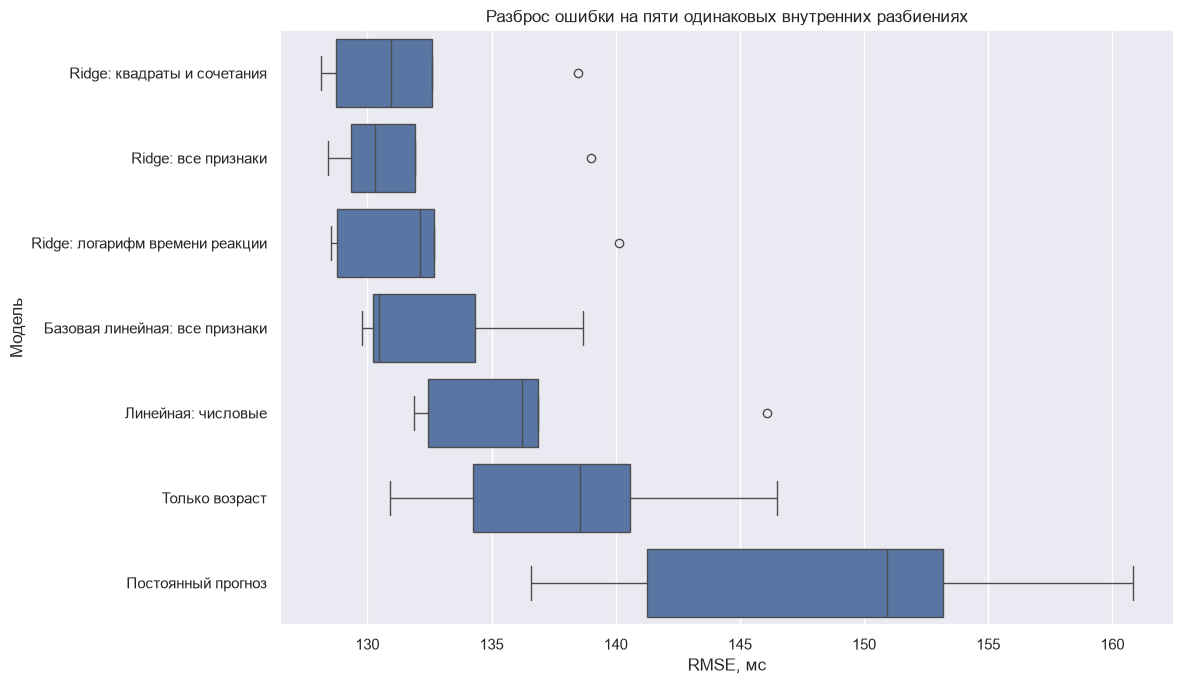

Предупреждений при подборе и проверке: 25
На некоторых внутренних разбиениях редкий уровень образования не встречается при обучении. Его кодируют нулевым блоком, как заранее задано в OneHotEncoder.
Уникальные предупреждения: ['Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros']


In [24]:
fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=fold_results, x='RMSE, мс', y='Модель', order=ranking['Модель'].tolist(), ax=ax)
ax.set_title('Разброс ошибки на пяти одинаковых внутренних разбиениях')
plt.tight_layout()
plt.show()

experiments.to_csv(ARTIFACTS / 'experiments.csv', index=False)
fold_results.to_csv(ARTIFACTS / 'cross_validation.csv', index=False)
search_tables = []
for name, search in [(RIDGE, ridge_search), (POLY, poly_search), (LOG, log_search)]:
    table = pd.DataFrame(search.cv_results_)
    table['Модель'] = name
    search_tables.append(table)
pd.concat(search_tables, ignore_index=True).to_csv(ARTIFACTS / 'parameter_search.csv', index=False)
selection = {'selected_model': selected_name, 'criterion': 'mean inner CV RMSE',
             'ridge_alpha': float(ridge_alpha), 'poly_alpha': float(poly_alpha),
             'log_alpha': float(log_alpha), 'random_state_test': 2026}
(ARTIFACTS / 'selection_before_test.json').write_text(
    json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
print('Предупреждений при подборе и проверке:', len(evaluation_warnings))
if evaluation_warnings:
    print('На некоторых внутренних разбиениях редкий уровень образования не встречается при обучении. Его кодируют нулевым блоком, как заранее задано в OneHotEncoder.')
    print('Уникальные предупреждения:', list(dict.fromkeys(evaluation_warnings)))

**Выбор.**   
По заранее выбранному критерию победил вариант «Ridge: квадраты и сочетания»: средний RMSE 131,78 мс, разброс 4,15 мс.    
У полной базовой модели RMSE 132,70 мс.   
Если различия малы по сравнению с разбросом, я не считаю их надёжно доказанными.   
Разница между обычной Ridge и вариантом с квадратами всего 0,02 мс, поэтому выигрыш квадратов здесь практически отсутствует.

## 8. Финальная проверка

Настройки и выбор модели уже зафиксированы в предыдущем разделе. Теперь обучаю постоянный прогноз, модель по возрасту, базовую LinearRegression и выбранную модель на всей обучающей части. Только здесь получаю прогнозы для финальной части и считаю её метрики. Далее использую сохранённые прогнозы для разбора ошибок; по этим результатам параметры не меняю.

В таблице RMSE и MAE меньше означает лучше, R2 больше означает лучше. Самый маленький показатель на финальной части не используется для повторного выбора модели.

In [25]:
final_models = {
    DUMMY: DummyRegressor(strategy='mean'),
    AGE: make_model(['age']),
    BASE: make_model(num_columns, cat_columns),
    'Выбранная модель': selected_model
}
test_rows = []
test_predictions = {}
for name, estimator in final_models.items():
    estimator.fit(X_train, y_train)
    prediction = estimator.predict(X_test)
    test_predictions[name] = prediction
    test_rows.append({'Модель': name, **metrics(y_test, prediction)})
test_metrics = pd.DataFrame(test_rows)
final_model = final_models['Выбранная модель']
final_pred = test_predictions['Выбранная модель']
test_metrics.to_csv(ARTIFACTS / 'final_metrics.csv', index=False)
test_metrics

,Модель,"MAE, мс","RMSE, мс",R2
0,Постоянный прогноз,125.688137,153.672870,-0.000357
1,Только возраст,114.175077,142.231162,0.143061
2,Базовая линейная: все признаки,108.257164,138.963530,0.181983
3,Выбранная модель,108.688835,139.852443,0.171484


**Итог на отложенных данных.**   
У выбранного варианта MAE 108,69 мс, RMSE 139,85 мс, R2 0.171.   
У постоянного прогноза RMSE 153,67 мс. Относительно постоянного прогноза RMSE уменьшился на 13,82 мс. 
У простой полной LinearRegression RMSE 138,96 мс: выбранный вариант оказался хуже на 0,89 мс. Это показывает, что небольшой выигрыш на внутренних разбиениях не гарантирует улучшения на отложенных строках.   

Даже при улучшении отдельные прогнозы могут сильно ошибаться, ниже разберу эти случаи.   
Выбор модели после просмотра этой таблицы не меняется.

### 8.1. Истинные значения, прогнозы и остатки
Левая диаграмма сравнивает измеренное и предсказанное время: близость к диагонали означает точный прогноз. Справа остатки против прогноза: положительные значения означают недооценку времени реакции.

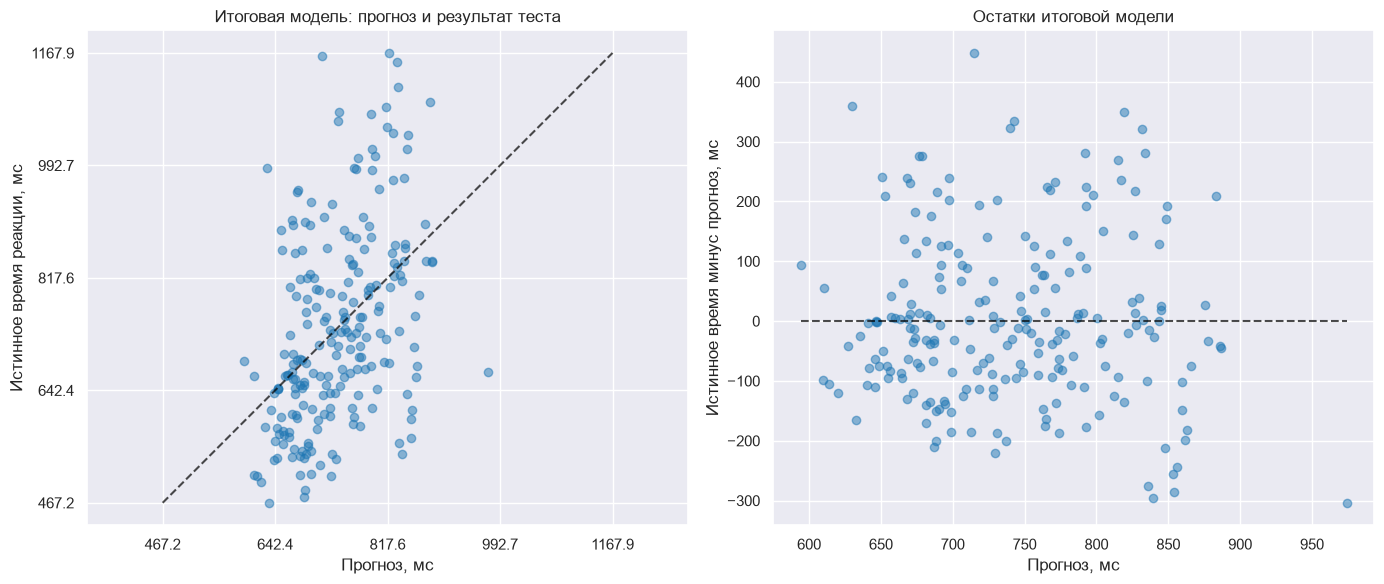

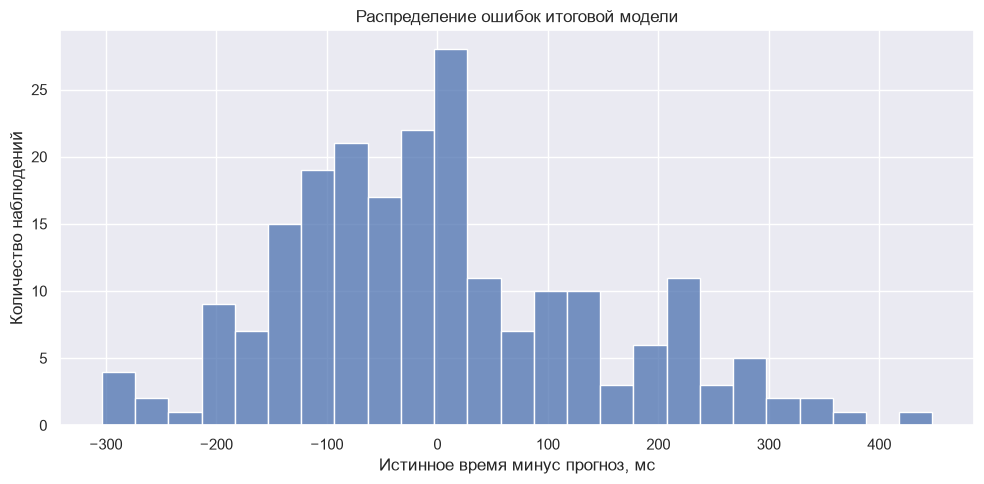

count    217.000000
mean       0.656018
std      140.174260
min     -303.641058
25%      -94.481715
50%      -14.527374
75%       82.234990
max      448.130703
Name: Остаток, dtype: float64

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
PredictionErrorDisplay.from_predictions(
    y_test, final_pred, kind='actual_vs_predicted', ax=ax[0],
    scatter_kwargs={'alpha': 0.5}, line_kwargs={'color': 'black'})
ax[0].set_xlabel('Прогноз, мс')
ax[0].set_ylabel('Истинное время реакции, мс')
ax[0].set_title('Итоговая модель: прогноз и результат теста')
PredictionErrorDisplay.from_predictions(
    y_test, final_pred, kind='residual_vs_predicted', ax=ax[1],
    scatter_kwargs={'alpha': 0.5}, line_kwargs={'color': 'black'})
ax[1].set_xlabel('Прогноз, мс')
ax[1].set_ylabel('Истинное время минус прогноз, мс')
ax[1].set_title('Остатки итоговой модели')
plt.tight_layout()
plt.show()

error_table = X_test.copy()
error_table['Истинное время'] = y_test
error_table['Прогноз'] = final_pred
error_table['Остаток'] = y_test - final_pred
error_table['Абсолютная ошибка'] = np.abs(y_test - final_pred)
plt.figure(figsize=(10, 5))
sns.histplot(data=error_table, x='Остаток', bins=25)
plt.xlabel('Истинное время минус прогноз, мс')
plt.ylabel('Количество наблюдений')
plt.title('Распределение ошибок итоговой модели')
plt.tight_layout()
plt.show()
error_table['Остаток'].describe()

### 8.2. Где ошибки больше
Границы трёх групп времени беру из квартилей цели обучающей части, а не подбираю по финальной. Группировка по истинному времени нужна только для анализа ошибок после теста; при реальном прогнозе группа ещё неизвестна.

In [27]:
low_time, high_time = y_train.quantile(0.25), y_train.quantile(0.75)
error_table['Группа времени'] = 'Среднее время'
error_table.loc[error_table['Истинное время'] < low_time, 'Группа времени'] = 'Быстрые ответы'
error_table.loc[error_table['Истинное время'] > high_time, 'Группа времени'] = 'Медленные ответы'

time_errors = error_table.groupby('Группа времени').agg(
    Наблюдений=('Остаток', 'count'),
    Средняя_абсолютная_ошибка=('Абсолютная ошибка', 'mean'),
    Средний_остаток=('Остаток', 'mean'))
print('Границы групп по обучающей части:', round(low_time, 2), round(high_time, 2))
time_errors

Границы групп по обучающей части: 632.63 839.08


,Наблюдений,Средняя_абсолютная_ошибка,Средний_остаток
Группа времени,,,
Быстрые ответы,54,137.883317,-137.883317
Медленные ответы,56,178.123270,173.817330
Среднее время,107,57.615654,-20.053416


In [28]:
grade_errors = error_table.groupby('grade').agg(
    Наблюдений=('Остаток', 'count'),
    Средняя_абсолютная_ошибка=('Абсолютная ошибка', 'mean'),
    Средний_остаток=('Остаток', 'mean'))
grade_errors

,Наблюдений,Средняя_абсолютная_ошибка,Средний_остаток
grade,,,
2nd,80,119.233590,-2.253212
3rd,79,105.386500,19.742912
4th,58,98.642353,-21.328918


In [29]:
print('Наибольшие ошибки:')
error_table.sort_values('Абсолютная ошибка', ascending=False)[
    ['age', 'grade', 'sex', 'no2_class', 'no2_home',
     'Истинное время', 'Прогноз', 'Остаток', 'Абсолютная ошибка']
].head(10)

Наибольшие ошибки:


,age,grade,sex,no2_class,no2_home,Истинное время,Прогноз,Остаток,Абсолютная ошибка
428,9.067761,3rd,Male,30.968130,44.292187,1162.926829,714.796127,448.130703,448.130703
145,10.839151,4th,Male,37.234077,52.768585,989.000000,629.642359,359.357641,359.357641
233,8.260096,2nd,Female,20.647024,22.936901,1167.916667,819.061818,348.854849,348.854849
127,8.884326,3rd,Male,18.629356,33.413204,1076.590551,742.353176,334.237375,334.237375
159,10.234086,4th,Female,42.043976,44.181816,1061.857143,739.687066,322.170077,322.170077
415,7.780972,2nd,Female,30.968130,52.643833,1153.344262,831.465535,321.878727,321.878727
474,8.101300,2nd,Female,52.563970,57.164898,670.503937,974.144995,-303.641058,303.641058
936,8.714579,2nd,Male,23.902954,45.126156,543.233871,839.588112,-296.354241,296.354241
815,7.835729,2nd,Male,27.422169,49.750034,567.414634,853.827175,-286.412541,286.412541
118,8.229980,2nd,Female,18.629356,31.730152,1115.574803,834.075696,281.499107,281.499107


In [30]:
print('Наименьшие ошибки:')
error_table.sort_values('Абсолютная ошибка')[
    ['age', 'grade', 'Истинное время', 'Прогноз', 'Абсолютная ошибка']
].head(5)

Наименьшие ошибки:


,age,grade,Истинное время,Прогноз,Абсолютная ошибка
379,10.414784,4th,646.051020,646.462248,0.411227
982,7.488022,2nd,844.123894,843.512281,0.611613
197,9.727584,3rd,731.448000,732.687741,1.239741
517,8.440794,2nd,751.850000,750.354325,1.495675
79,8.643394,3rd,712.816000,711.310744,1.505256


**Наблюдение.**   
Самая низкая средняя абсолютная ошибка среди групп времени у группы «Среднее время», самая высокая у группы «Медленные ответы».   
Средние остатки приведены рядом: их знак показывает направление ошибки. Самая большая ошибка отдельной строки составляет 448,13 мс при истинном времени 1162,93 мс и прогнозе 714,80 мс.   
Попадание в список больших ошибок не доказывает ошибочность самой записи.   
Различия между классами оцениваю с учётом числа строк в группах, а удачный прогноз отдельной строки не означает надёжность для всех похожих детей.

## 9. Коэффициенты модели

Имена признаков получаю из обученного `ColumnTransformer`, а коэффициенты из `coef_` модели.   
Числовые показатели масштабированы, поэтому их коэффициенты относятся к изменению на одно обучающее стандартное отклонение.   
Категориальный коэффициент сравнивает категорию с базовой, показанной ниже.

Для полиномов отдельный коэффициент квадрата или произведения нельзя трактовать как постоянный эффект одного исходного показателя: прогноз зависит и от других слагаемых.   
Если выбрана модель с преобразованием цели, коэффициенты описывают логарифм времени, а не прибавку миллисекунд.   
Во всех случаях это параметры прогноза, а не причинные эффекты NO2 или семейных характеристик.

In [31]:
feature_names = final_model['preprocessors'].get_feature_names_out()
regression = final_model['model']
target_is_log = isinstance(regression, TransformedTargetRegressor)
if target_is_log:
    regression = regression.regressor_
coefficient_table = pd.DataFrame({'Признак': feature_names, 'Коэффициент': regression.coef_})
coefficient_table['Модуль'] = np.abs(coefficient_table['Коэффициент'])
print('Свободный коэффициент:', regression.intercept_)
print('Коэффициенты относятся к логарифму цели:', target_is_log)
coefficient_table.sort_values('Модуль', ascending=False).head(15)

Свободный коэффициент: 785.9679541725708
Коэффициенты относятся к логарифму цели: False


,Признак,Коэффициент,Модуль
18,cat__grade_3rd,-47.964995,47.964995
17,cat__sex_Male,-46.377799,46.377799
19,cat__grade_4th,-45.797647,45.797647
28,cat__feducation_Primary,40.646308,40.646308
25,cat__meducation_Primary,29.564711,29.564711
8,poly__no2_home^2,-26.106086,26.106086
6,poly__no2_class^2,23.623035,23.623035
4,poly__age no2_class,-21.606085,21.606085
0,poly__age,-19.699249,19.699249
7,poly__no2_class no2_home,18.182726,18.182726


In [32]:
encoder = final_model['preprocessors'].named_transformers_['cat']['encoder']
reference_categories = pd.DataFrame({
    'Признак': cat_columns,
    'Базовая категория': [categories[index] for categories, index
                         in zip(encoder.categories_, encoder.drop_idx_)]
})
reference_categories

,Признак,Базовая категория
0,sex,Female
1,grade,2nd
2,overweight,Normal weight
3,lbweight,Low birthweight
4,breastfeed,<6 months
5,msmoke,No smoking
6,meducation,<Primary
7,feducation,<Primary


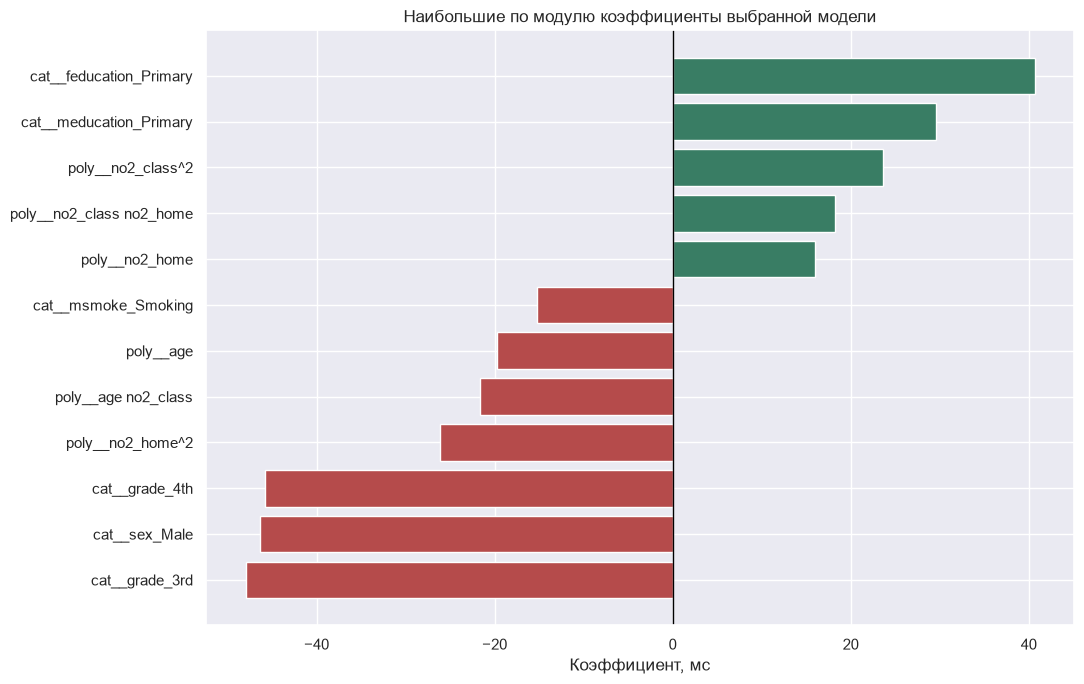

In [33]:
top_coefs = coefficient_table.sort_values('Модуль', ascending=False).head(12).sort_values('Коэффициент')
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(top_coefs['Признак'], top_coefs['Коэффициент'],
        color=['#b54b4b' if value < 0 else '#397d64' for value in top_coefs['Коэффициент']])
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Наибольшие по модулю коэффициенты выбранной модели')
ax.set_xlabel('Коэффициент в логарифме времени' if target_is_log else 'Коэффициент, мс')
plt.tight_layout()
plt.show()

**Наблюдение.**   
Среди самых больших по модулю коэффициентов: cat__grade_3rd, cat__sex_Male, cat__grade_4th, cat__feducation_Primary, cat__meducation_Primary.   
Этот список не является рейтингом причин и не доказывает, что один признак полезнее всех остальных.

## 10. Десять новых хитрых примеров

Создаю десять вымышленных строк с теми же столбцами. Основой служат медианы числовых и самые частые категории обучающей части. Это не реальные дети и не готовые размеченные наблюдения, поэтому для них нельзя посчитать качество прогноза.

Проверяю обычный случай, края возраста, низкое и высокое загрязнение, полное отсутствие числовых или категориальных данных, неизвестные категории, возраст за пределами выборки и заведомо некорректный ввод.

На ошибочных и выходящих за изученный диапазон строках прогноз показывается только как демонстрация поведения модели. Получение числа не делает такой прогноз достоверным. Обычная линейная модель не умеет сама проверять физический смысл значений.

In [34]:
base_object = {name: X_train[name].median() for name in num_columns}
base_object.update({name: X_train[name].mode().iloc[0] for name in cat_columns})
cases = [
    ('Обычные характеристики', {}, 'Внутри обычного диапазона'),
    ('Младший ребёнок', {'age': 7.5, 'grade': '2nd'}, 'Край возрастного диапазона'),
    ('Старший ребёнок', {'age': 11.5, 'grade': '4th'}, 'Край возрастного диапазона'),
    ('Очень низкий NO2', {'no2_class': 5.0, 'no2_home': 5.0}, 'Школьный NO2 ниже изученного диапазона'),
    ('Высокий NO2 и шум', {'no2_class': 100.0, 'no2_home': 180.0, 'noise_school': 65.0},
     'Выход за изученные диапазоны'),
    ('Нет числовых данных', {name: np.nan for name in num_columns}, 'Все числа будут заполнены медианами'),
    ('Нет категориальных данных', {name: np.nan for name in cat_columns}, 'Категории будут заполнены модами'),
    ('Неизвестные категории', {'sex': 'Unknown', 'grade': '5th', 'meducation': 'NewEducation'},
     'Неизвестные значения дадут нулевые блоки'),
    ('Возраст вне выборки', {'age': 16.0, 'grade': '4th'}, 'Экстраполяция на другой возраст'),
    ('Некорректные значения', {'age': 9.0, 'age0': 15.0, 'no2_home': -10.0, 'precip': -1.0},
     'Отрицательные загрязнение и осадки, поступление в школу позже текущего возраста')
]
new_objects = []
for title, changes, comment in cases:
    row = base_object.copy()
    row.update(changes)
    new_objects.append(row)
X_new = pd.DataFrame(new_objects, columns=feature_columns)
with warnings.catch_warnings(record=True) as unknown_warnings:
    new_predictions = final_model.predict(X_new)

new_result = pd.DataFrame({
    'Пример': [item[0] for item in cases],
    'Прогноз, мс': new_predictions,
    'Комментарий': [item[2] for item in cases]
})
new_result['Положительный конечный прогноз'] = np.isfinite(new_predictions) & (new_predictions > 0)
print('Предупреждения о новых категориях:', len(unknown_warnings))
for item in unknown_warnings:
    print(str(item.message))
new_result

Предупреждения о новых категориях: 1
Found unknown categories in columns [0, 1, 6] during transform. These unknown categories will be encoded as all zeros


,Пример,"Прогноз, мс",Комментарий,Положительный конечный прогноз
0,Обычные характеристики,713.815934,Внутри обычного диапазона,True
1,Младший ребёнок,778.728279,Край возрастного диапазона,True
2,Старший ребёнок,558.909279,Край возрастного диапазона,True
3,Очень низкий NO2,658.698777,Школьный NO2 ниже изученного диапазона,True
4,Высокий NO2 и шум,1089.850106,Выход за изученные диапазоны,True
5,Нет числовых данных,713.815934,Все числа будут заполнены медианами,True
6,Нет категориальных данных,713.815934,Категории будут заполнены модами,True
7,Неизвестные категории,761.156453,Неизвестные значения дадут нулевые блоки,True
8,Возраст вне выборки,333.625506,Экстраполяция на другой возраст,True
9,Некорректные значения,718.494985,"Отрицательные загрязнение и осадки, поступлени...",True


**Результат.** 
Для всех десяти строк получены прогнозы.   
Диапазон: от 333,63 до 1089,85 мс; 
положительных конечных прогнозов 10 из 10. 
Пропуски заполнены внутри пайплайна, а неизвестные категории обработаны кодировщиком.   

Для шестого и седьмого примеров результат во многом определяется подставленными типичными значениями. 
Последняя строка показывает ограничение: даже заведомо неверные значения могут превратиться в обычное число. 
Такие данные нужно проверять до использования прогноза.   

### Сохранение и проверка готовой модели
Сохраняю весь пайплайн, включая предобработку. После загрузки проверяю совпадение прогнозов на новых объектах.

In [35]:
dump(final_model, ARTIFACTS / 'reaction_model.joblib')
loaded_model = load(ARTIFACTS / 'reaction_model.joblib')
with warnings.catch_warnings(record=True):
    loaded_prediction = loaded_model.predict(X_new)
    transformed_new = final_model['preprocessors'].transform(X_new)
checks = {
    'Обучающие и финальные строки не пересекаются':
        len(X_train.index.intersection(X_test.index)) == 0,
    'Цель и результаты теста не входят в признаки':
        all(name not in feature_columns for name in ['react', 'correct', 'omissions']),
    'Во внутренней проверке пять одинаковых разбиений': len(cv_splits) == 5,
    'Все семь экспериментов завершены': len(experiments) == 7,
    'Выбор соответствует внутреннему RMSE': selected_name == eligible.iloc[0]['Модель'],
    'Параметры заполнения чисел рассчитаны только по обучающей части':
        np.allclose(final_model['preprocessors'].named_transformers_[
            'poly' if selected_name == POLY else 'num']['imputer'].statistics_,
            X_train[['age', 'no2_class', 'no2_home'] if selected_name == POLY else num_columns].median()),
    'Итоговый прогноз конечен': np.isfinite(final_pred).all(),
    'Созданы ровно десять новых объектов': len(X_new) == len(new_predictions) == 10,
    'Предобработка новых объектов даёт конечные числа':
        np.isfinite(transformed_new).all(),
    'После загрузки прогнозы совпадают': np.allclose(new_predictions, loaded_prediction)
}
check_table = pd.DataFrame({'Проверка': list(checks), 'Пройдена': list(checks.values())})
assert check_table['Пройдена'].all()
print('Все проверки пройдены:', check_table['Пройдена'].all())

error_table.to_csv(ARTIFACTS / 'final_errors.csv', index_label='Исходная строка')
coefficient_table.to_csv(ARTIFACTS / 'coefficients.csv', index=False)
new_result.to_csv(ARTIFACTS / 'new_predictions.csv', index=False)
X_new.to_csv(ARTIFACTS / 'new_objects.csv', index=False)
check_table.to_csv(ARTIFACTS / 'checks.csv', index=False)
check_table

Все проверки пройдены: True


,Проверка,Пройдена
0,Обучающие и финальные строки не пересекаются,True
1,Цель и результаты теста не входят в признаки,True
2,Во внутренней проверке пять одинаковых разбиений,True
3,Все семь экспериментов завершены,True
4,Выбор соответствует внутреннему RMSE,True
5,Параметры заполнения чисел рассчитаны только п...,True
6,Итоговый прогноз конечен,True
7,Созданы ровно десять новых объектов,True
8,Предобработка новых объектов даёт конечные числа,True
9,После загрузки прогнозы совпадают,True


## 11. Итоговые выводы

1. **Есть ли польза от признаков** На внутренней проверке постоянный прогноз дал RMSE 148,55 мс, а полная базовая модель 132,70 мс. Разница позволяет оценить пользу доступных характеристик по сравнению с одним средним.
2. **Если судить только по возрасту** RMSE уменьшился на 10,38 мс. Это примерно 65,51% уменьшения ошибки полной базовой модели относительно постоянного прогноза. Это правильно выбранный признак и он уже содержит часть информации, но не объясняет различия всех детей.
3. **Сравнение по дополнительным признакам** При добавлении категорий к числовым признакам Средний RMSE уменьшился на 4,01 мс. 
4. **Регуляризация** Средний RMSE уменьшился на 0,89 мс. Для обычной Ridge выбрана alpha=10. Пока не вижу в этом пользы.
5. **Усложнение и преобразование цели** При добавлении квадратов относительно Ridge средний rmse уменьшился на 0,02 мс. При логарифмировании цели относительно Ridge средний rmse увеличился на 0,65 мс. Ухудшение показывает, что приём не помогает сделать выводы по времени реакции.
6. **Выбранный вариант** По внутреннему RMSE выбран «Ridge: квадраты и сочетания». На финальной части MAE составила 108,69 мс, RMSE 139,85 мс и R2 0.171. У простой полной LinearRegression финальный RMSE 138,96 мс. Усложнение не обеспечило уверенного улучшения: на внутренних разбиениях разница была очень мала, а финальная проверка даёт основание осторожно относиться к выбранному победителю. 
7. **Где проявились ограничения.** Наибольшая ошибка финальной части 448,13 мс, при этом средняя ошибка больше в группе «Медленные ответы». Большой разброс реакции при похожих признаках снижает точность.
8. **Новые данные** Проверены десять хитрых примеров с пропусками, неизвестными категориями и необычными значениями. Технически прогноз получается, но надежности оценки он не добавляет.

### Ограничения и доверие к прогнозам

По этим данным можно изучить качество прогноза времени реакции, но нельзя доказать конкретную причину - влияние NO2. 

Выборка оказалась небольшая. Редкие категории, пропуски и неизвестная структура измерений ограничивают выводы. Стандартное отклонение пяти ошибок не является статистическим доказательством превосходства модели. 

При другом возрасте, новых категориях, необычном загрязнении и неверном вводе доверять модели уже будет невозможно. 


### Сохранённые результаты
В `lab2_artifacts` будут сохраняться артефакты каждого этапа.
`reaction_model.joblib` - это файл с уже обученной моделью:
- заполнение пропусков
- кодирование категориальных признаков
- масштабирование
- создание полиномиальных признаков
- обученная модель Ridge и её коэффициенты

Благодаря этому модель можно загрузить и сразу использовать, не обучая заново командой:
```python
import joblib

model = joblib.load('lab2_artifacts/reaction_model.joblib')
predictions = model.predict(new_data)
```
